In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

ROLL_NUMBER=4049065
np.random.seed(ROLL_NUMBER)
rng=np.random.default_rng(ROLL_NUMBER)
kdd = fetch_kddcup99(subset=None, as_frame=True)

In [2]:
X=kdd.data
y=kdd.target
print(X.shape)
print(y.shape)
onehot=['protocol_type','service','flag']
X=pd.get_dummies(X, columns=onehot, dtype=float)
dropped=[]
for i in range(len(X.columns)):
  col=X.columns[i]
  if(col not in onehot):
    X[col]=X[col].astype(float)
  maxi=X[col].max()
  mini=X[col].min()
  if(maxi==mini):
    dropped.append(col)
  else:
    X[col]=(X[col]-mini)/(maxi-mini)

for i in range(len(dropped)):
  X=X.drop(dropped[i], axis=1)
print(X.shape)

(494021, 41)
(494021,)
(494021, 116)


In [3]:
D=X.to_numpy()
n=D.shape[0]
d=D.shape[1]
m=[5,10,15,20,25]
time_all=[]
B=[]
labels_DE=[]
costs_hat=[]
ratios_hat=[]
costs_plus=[]
ratios_plus=[]

start=time.perf_counter()
km= KMeans(n_clusters=15, n_init=5, random_state=ROLL_NUMBER)
km.fit(D)
base_time=time.perf_counter()-start
base_B=km.cluster_centers_
base_labels=km.labels_
base_cost=km.inertia_
print("Wall clock time (s):", base_time)
print("Cost (D,B):", base_cost)


Wall clock time (s): 17.821124346000033
Cost (D,B): 54522.25659442802


In [4]:
def cost_D(D, centres):
  best= np.full(D.shape[0], np.inf)
  for j in range(len(centres)):
    dist=np.sum((D-centres[j])**2, axis=1)
    best=np.minimum(best, dist)
  return best.sum()

for i in range(len(m)):
  time_all.append([])
  B.append([])
  labels_DE.append([])
  costs_hat.append([])
  ratios_hat.append([])
  costs_plus.append([])
  ratios_plus.append([])
  for j in range(5):
    A=rng.normal(0, 1/np.sqrt(m[i]), size=(m[i], d))
    start=time.perf_counter()

    E= D@A.T
    km.fit(E)
    time_all[-1].append(time.perf_counter()-start)
    A_plus=np.linalg.pinv(A)
    B[-1].append(km.cluster_centers_)
    labels_DE[-1].append(km.labels_)
    labels=labels_DE[-1][-1]
    B_hat=[]
    B_plus=[]
    for c in range(15):
      B_hat.append(D[labels==c].mean(axis=0))
      B_plus.append(A_plus@B[-1][-1][c])
    B_hat=np.array(B_hat)
    B_plus=np.array(B_plus)
    cost_hat=cost_D(D, B_hat)
    cost_plus=cost_D(D, B_plus)
    costs_hat[-1].append(cost_hat)
    costs_plus[-1].append(cost_plus)
    ratios_hat[-1].append(cost_hat/base_cost)
    ratios_plus[-1].append(cost_plus/base_cost)
    print("Cost (D,B_hat)"+" | m = "+str(m[i])+" | Iteration = "+str(j+1)+": ",costs_hat[-1][-1])
    print("Cost (D,B_plus)"+" | m = "+str(m[i])+" | Iteration = "+str(j+1)+": ",costs_plus[-1][-1])
    print("Cost (D,B_hat) Ratio:", ratios_hat[-1][-1])
    print("Cost (D,B_plus) Ratio:", ratios_plus[-1][-1])


Cost (D,B_hat) | m = 5 | Iteration = 1:  61452.12633983842
Cost (D,B_plus) | m = 5 | Iteration = 1:  4368431.231406005
Cost (D,B_hat) Ratio: 1.1271016678007162
Cost (D,B_plus) Ratio: 80.12198144880972
Cost (D,B_hat) | m = 5 | Iteration = 2:  65021.2199008832
Cost (D,B_plus) | m = 5 | Iteration = 2:  4299152.497914437
Cost (D,B_hat) Ratio: 1.1925628901340841
Cost (D,B_plus) Ratio: 78.85133093250941
Cost (D,B_hat) | m = 5 | Iteration = 3:  66209.58948262958
Cost (D,B_plus) | m = 5 | Iteration = 3:  4143980.9106018604
Cost (D,B_hat) Ratio: 1.2143589355653333
Cost (D,B_plus) Ratio: 76.00530809697558
Cost (D,B_hat) | m = 5 | Iteration = 4:  63366.629000191286
Cost (D,B_plus) | m = 5 | Iteration = 4:  4207026.795804494
Cost (D,B_hat) Ratio: 1.1622158171396584
Cost (D,B_plus) Ratio: 77.16164110922799
Cost (D,B_hat) | m = 5 | Iteration = 5:  62631.317800108154
Cost (D,B_plus) | m = 5 | Iteration = 5:  4374030.104081379
Cost (D,B_hat) Ratio: 1.1487293760784811
Cost (D,B_plus) Ratio: 80.22467112

,m,Mean ratio,Min ratio,Max ratio
0,5,1.168994,1.127102,1.214359
1,10,1.075260,0.979931,1.195321
2,15,1.017755,0.963174,1.104949
3,20,1.001781,0.975113,1.038810
4,25,1.001713,0.959796,1.038410


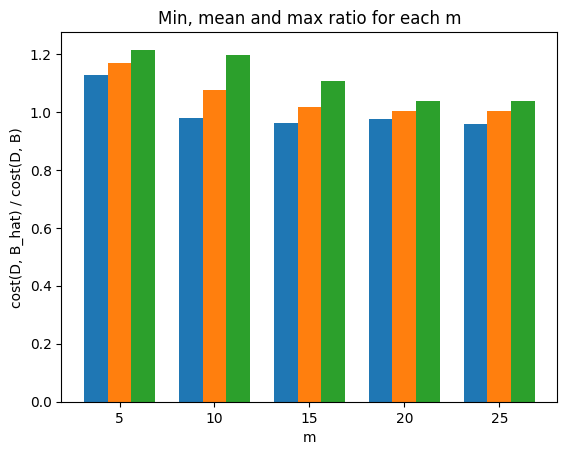

In [5]:
mean_hat=[]
min_hat=[]
max_hat=[]
for i in range(len(m)):
  total=0
  for j in range(5):
    total+= ratios_hat[i][j]
  mean_hat.append(total/5)
  min_hat.append(min(ratios_hat[i]))
  max_hat.append(max(ratios_hat[i]))

summary= pd.DataFrame({'m': m, 'Mean ratio': mean_hat, 'Min ratio': min_hat, 'Max ratio': max_hat})
display(summary)

plt.bar([i-0.25 for i in range(len(m))], min_hat, width=0.25)
plt.bar(range(len(m)), mean_hat, width=0.25)
plt.bar([i+0.25 for i in range(len(m))], max_hat, width=0.25)
plt.xticks(range(len(m)), m)
plt.xlabel('m')
plt.ylabel('cost(D, B_hat) / cost(D, B)')
plt.title('Min, mean and max ratio for each m')
plt.show()

In [6]:
mean_plus=[]
min_plus=[]
max_plus=[]
for i in range(len(m)):
  total=0
  for j in range(5):
    total+= ratios_plus[i][j]
  mean_plus.append(total/5)
  min_plus.append(min(ratios_plus[i]))
  max_plus.append(max(ratios_plus[i]))

summary= pd.DataFrame({'m': m, 'B_plus mean ratio': mean_plus, 'B_hat mean ratio': mean_hat})
display(summary)


,m,B_plus mean ratio,B_hat mean ratio
0,5,78.472987,1.168994
1,10,74.891633,1.075260
2,15,70.788152,1.017755
3,20,68.099700,1.001781
4,25,64.385147,1.001713


,m,Mean time (s)
0,5,4.644876
1,10,4.808025
2,15,5.454379
3,20,6.218962
4,25,7.992754


Time for k-means on D (s): 17.821124346000033


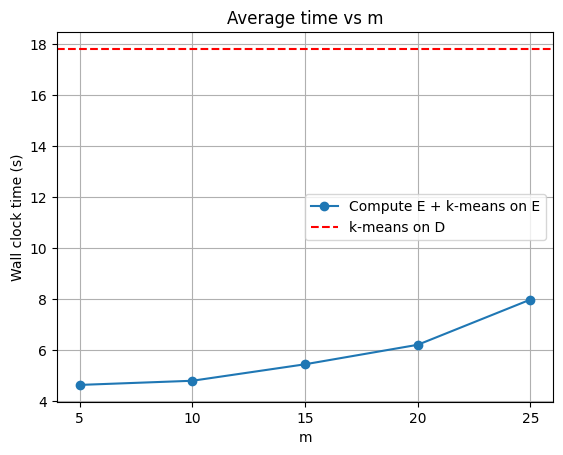

In [7]:
mean_time=[]
for i in range(len(m)):
  total=0
  for j in range(5):
    total+=time_all[i][j]
  mean_time.append(total/5)

times= pd.DataFrame({'m': m, 'Mean time (s)': mean_time})
display(times)
print("Time for k-means on D (s):", base_time)

plt.plot(m, mean_time, marker='o', label='Compute E + k-means on E')
plt.axhline(base_time, color='red', linestyle='--', label='k-means on D')
plt.xticks(m)
plt.xlabel('m')
plt.ylabel('Wall clock time (s)')
plt.title('Average time vs m')
plt.legend()
plt.grid(True)
plt.show()

In [8]:
def cost_part(X, labels):
  total=0
  for c in range(15):
    X_c=X[labels==c]
    mu=X_c.mean(axis=0)
    total+=np.sum((X_c-mu)**2)
  return total

pairs_i=[]
pairs_l=[]
pair_ratio=[]
pair_cost_ratio=[]
while len(pairs_i)<10000:
  i= rng.integers(0, n)
  l= rng.integers(0, n)
  if np.any(D[i]!=D[l]):
    pairs_i.append(i)
    pairs_l.append(l)
pairs_i= np.array(pairs_i)
pairs_l= np.array(pairs_l)

D_i=D[pairs_i]
D_l=D[pairs_l]
den=np.sum((D_i-D_l)**2, axis=1)
cost_CD=cost_part(D, base_labels)

for i in range(len(m)):
  pair_cost_ratio.append([])
  for j in range(20):
    A=rng.normal(0, 1/np.sqrt(m[i]), size=(m[i], d))
    if(j==0):
      E_i=D_i@A.T
      E_l=D_l@A.T
      num=np.sum((E_i-E_l)**2, axis=1)
      pair_ratio.append(num/den)
    E=D@A.T
    pair_cost_ratio[-1].append(cost_part(E, base_labels)/cost_CD)

/tmp/ipykernel_6642/2602860577.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(pair_ratio, labels=m)


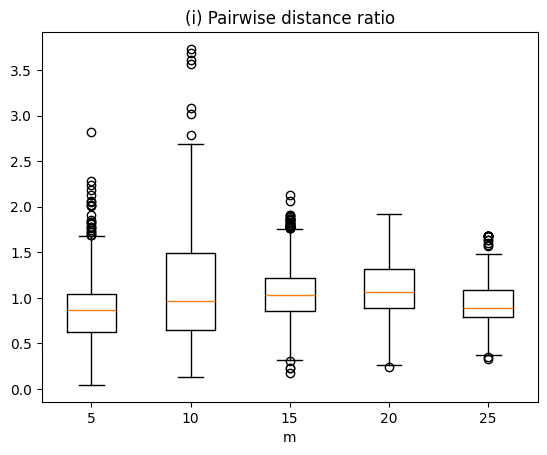

/tmp/ipykernel_6642/2602860577.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(pair_cost_ratio, labels=m)


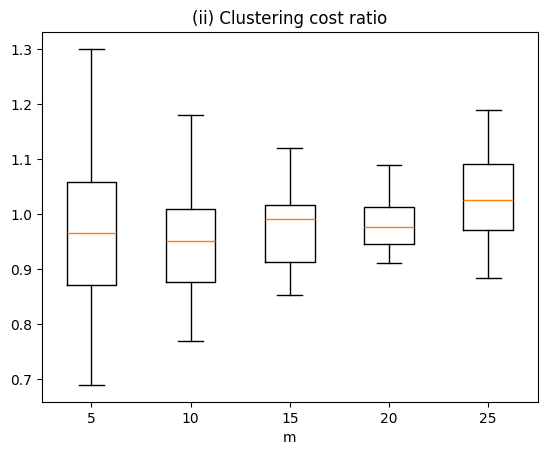

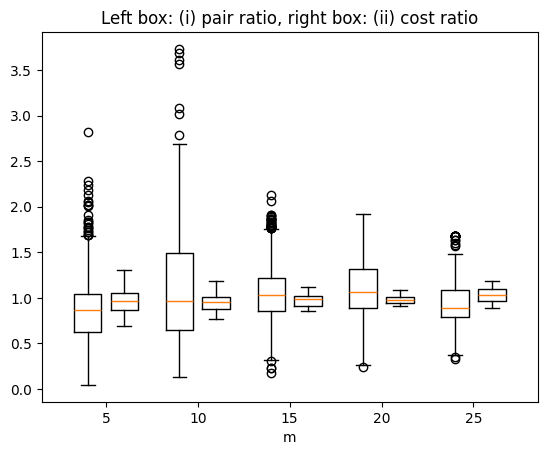

In [9]:
plt.boxplot(pair_ratio, labels=m)
plt.xlabel('m')
plt.title('(i) Pairwise distance ratio')
plt.show()

plt.boxplot(pair_cost_ratio, labels=m)
plt.xlabel('m')
plt.title('(ii) Clustering cost ratio')
plt.show()

plt.boxplot(pair_ratio, positions=[1, 2, 3, 4, 5], widths=0.3)
plt.boxplot(pair_cost_ratio, positions=[1.4, 2.4, 3.4, 4.4, 5.4], widths=0.3)
plt.xticks([1.2, 2.2, 3.2, 4.2, 5.2], m)
plt.xlabel('m')
plt.title('Left box: (i) pair ratio, right box: (ii) cost ratio')
plt.show()